# 01 - Análisis exploratorio de datos

**Proyecto:** Predicción de inasistencias a turnos médicos.

**Objetivo:** describir el dataset, detectar patrones, generar las figuras del informe y dejar documentadas las hipótesis para el modelado.

**Dataset:** `data/processed/turnos_clean.parquet` (110.527 turnos, 33 columnas).

## 1. Configuración e importaciones

In [38]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


def find_project_root(start: Path) -> Path:
    """Busca hacia arriba la carpeta que contiene data/processed/turnos_clean.parquet."""
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "processed" / "turnos_clean.parquet").exists():
            return candidate
    return start


ROOT = find_project_root(Path.cwd())
DATA = ROOT / "data" / "processed" / "turnos_clean.parquet"
FIGURES = ROOT / "reports" / "figuras"
REPORTS = ROOT / "reports"
FIGURES.mkdir(parents=True, exist_ok=True)

if not DATA.exists():
    raise FileNotFoundError(
        f"No se encontro el dataset en {DATA}. "
        "Abri el notebook desde la carpeta del proyecto o ejecuta primero "
        "src/01_carga_validacion.py, src/02_limpieza.py y src/03_features.py."
    )

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10
pd.set_option("display.max_columns", 50)

df = pd.read_parquet(DATA)
print("Filas x columnas:", df.shape)
print("Columnas:", df.columns.tolist())


Filas x columnas: (110527, 33)
Columnas: ['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay', 'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'scheduled_date', 'appointment_date', 'waiting_days', 'waiting_days_bucket', 'waiting_days_corrected', 'is_same_day', 'appointment_weekday', 'appointment_weekday_name', 'appointment_week', 'appointment_month', 'is_weekend', 'scheduled_weekday', 'scheduled_hour', 'age_group', 'age_imputed', 'age_capped', 'chronic_conditions', 'has_chronic_condition', 'handicap_any', 'no_show']


## 2. Calidad general y variable objetivo

In [39]:
resumen_general = pd.Series(
    {
        "turnos": len(df),
        "tasa_no_show": df["no_show"].mean(),
        "pacientes_unicos": df["PatientId"].nunique(),
        "barrios": df["Neighbourhood"].nunique(),
        "turnos_unicos": df["AppointmentID"].nunique(),
    },
    name="valor",
).to_frame()
display(resumen_general)

display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("nulos"))
display(df[["Age", "waiting_days"]].describe().round(2))

,valor
turnos,110527.000000
tasa_no_show,0.201933
pacientes_unicos,62299.000000
barrios,81.000000
turnos_unicos,110527.000000


,nulos
PatientId,0
waiting_days_corrected,0
handicap_any,0
has_chronic_condition,0
chronic_conditions,0
age_capped,0
age_imputed,0
age_group,0
scheduled_hour,0
scheduled_weekday,0


,Age,waiting_days
count,110527.00,110527.00
mean,37.09,10.18
std,23.11,15.25
min,0.00,0.00
25%,18.00,0.00
50%,37.00,4.00
75%,55.00,15.00
max,100.00,179.00


,conteo,porcentaje
Asistió (0),88208,79.81
No asistió (1),22319,20.19


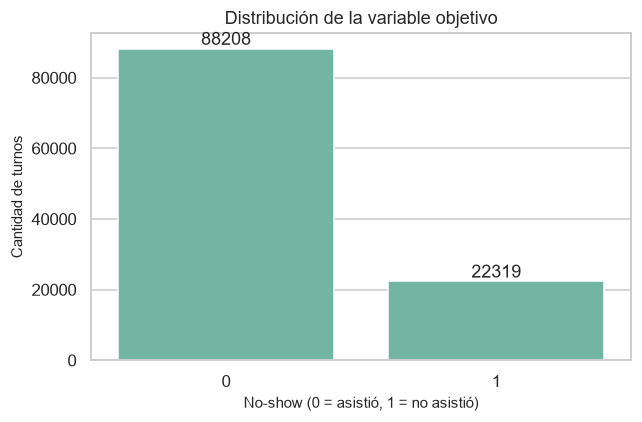

In [40]:
conteo = df["no_show"].value_counts().sort_index()
tabla_target = pd.DataFrame(
    {
        "conteo": conteo,
        "porcentaje": (conteo / len(df) * 100).round(2),
    }
)
tabla_target.index = ["Asistió (0)", "No asistió (1)"]
display(tabla_target)

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="no_show", ax=ax)
ax.set_title("Distribución de la variable objetivo")
ax.set_xlabel("No-show (0 = asistió, 1 = no asistió)")
ax.set_ylabel("Cantidad de turnos")
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
plt.tight_layout()
plt.savefig(FIGURES / "01_target_distribution.png", bbox_inches="tight")
plt.show()

**Lectura:** la clase positiva representa el **20,19 %**. Un modelo que prediga siempre “asiste” tendría 79,81 % de accuracy y detectaría cero no-shows. Por eso el modelado se evaluará con **recall, F1, ROC-AUC y PR-AUC**, no solo con accuracy.

## 3. Demora entre reserva y cita

,waiting_days_bucket,n,tasa,tasa_porcentaje
0,0,38568,0.046593,4.66
1,1-7,32185,0.241479,24.15
2,8-14,12025,0.304699,30.47
3,15-30,17371,0.325888,32.59
4,>30,10378,0.330025,33.00


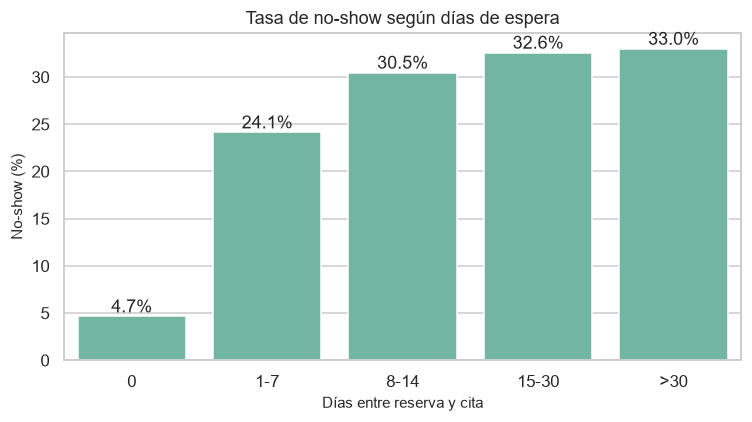

In [41]:
orden_demora = ["0", "1-7", "8-14", "15-30", ">30"]
tabla_demora = (
    df.groupby("waiting_days_bucket", observed=True)["no_show"]
    .agg(n="size", tasa="mean")
    .reindex(orden_demora)
    .reset_index()
)
tabla_demora["tasa_porcentaje"] = (tabla_demora["tasa"] * 100).round(2)
display(tabla_demora)
tabla_demora.to_csv(
    REPORTS / "eda_tabla_demora.csv", index=False, encoding="utf-8-sig"
)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=tabla_demora,
    x="waiting_days_bucket",
    y="tasa_porcentaje",
    ax=ax,
)
ax.set_title("Tasa de no-show según días de espera")
ax.set_xlabel("Días entre reserva y cita")
ax.set_ylabel("No-show (%)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
plt.tight_layout()
plt.savefig(FIGURES / "02_no_show_by_waiting_days.png", bbox_inches="tight")
plt.show()

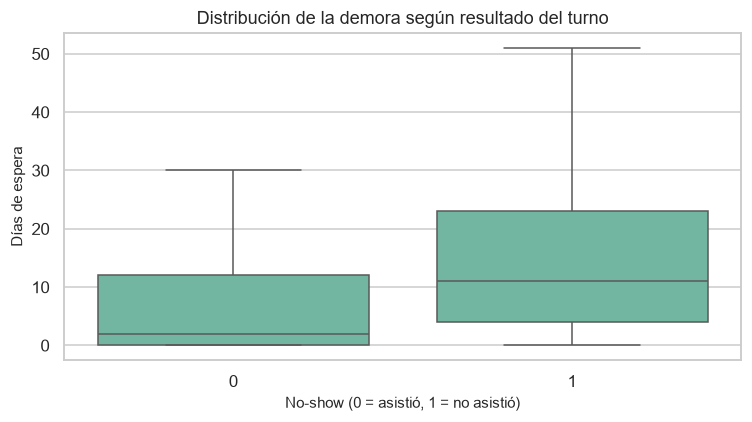

In [42]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(
    data=df,
    x="no_show",
    y="waiting_days",
    ax=ax,
    showfliers=False,
)
ax.set_title("Distribución de la demora según resultado del turno")
ax.set_xlabel("No-show (0 = asistió, 1 = no asistió)")
ax.set_ylabel("Días de espera")
plt.tight_layout()
plt.savefig(FIGURES / "03_waiting_days_distribution.png", bbox_inches="tight")
plt.show()

**Lectura:** la demora es el patrón más fuerte del dataset. Los turnos del mismo día tienen una tasa de no-show mucho menor que los turnos agendados con varios días de anticipación. La relación no es perfectamente lineal: se estabiliza alrededor de los 15 días.

## 4. SMS recibido

,SMS_received,n,tasa,grupo,tasa_porcentaje
0,0,75045,0.167033,Sin SMS,16.70
1,1,35482,0.275745,Con SMS,27.57


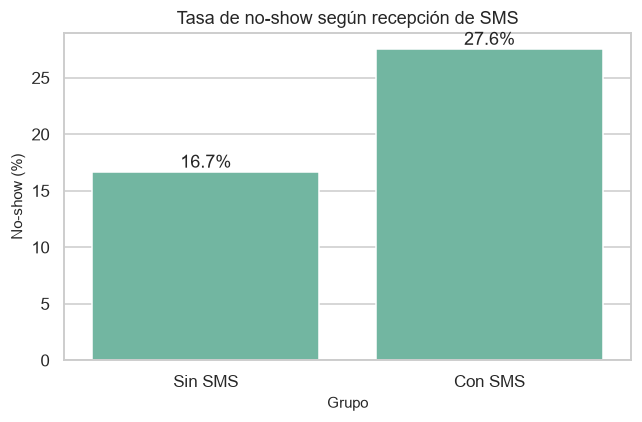

In [43]:
tabla_sms = (
    df.groupby("SMS_received", observed=True)["no_show"]
    .agg(n="size", tasa="mean")
    .reset_index()
)
tabla_sms["grupo"] = tabla_sms["SMS_received"].map({0: "Sin SMS", 1: "Con SMS"})
tabla_sms["tasa_porcentaje"] = (tabla_sms["tasa"] * 100).round(2)
display(tabla_sms)
tabla_sms.to_csv(
    REPORTS / "eda_tabla_sms.csv", index=False, encoding="utf-8-sig"
)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=tabla_sms, x="grupo", y="tasa_porcentaje", ax=ax)
ax.set_title("Tasa de no-show según recepción de SMS")
ax.set_xlabel("Grupo")
ax.set_ylabel("No-show (%)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
plt.tight_layout()
plt.savefig(FIGURES / "04_no_show_by_sms.png", bbox_inches="tight")
plt.show()

**Lectura:** el grupo con SMS tiene más no-show. Esto **no significa que el SMS cause la ausencia**: es probable que el mensaje se haya enviado a pacientes de mayor riesgo. La variable se mantiene como feature, pero se interpreta como asociación y no como causalidad.

## 5. Edad

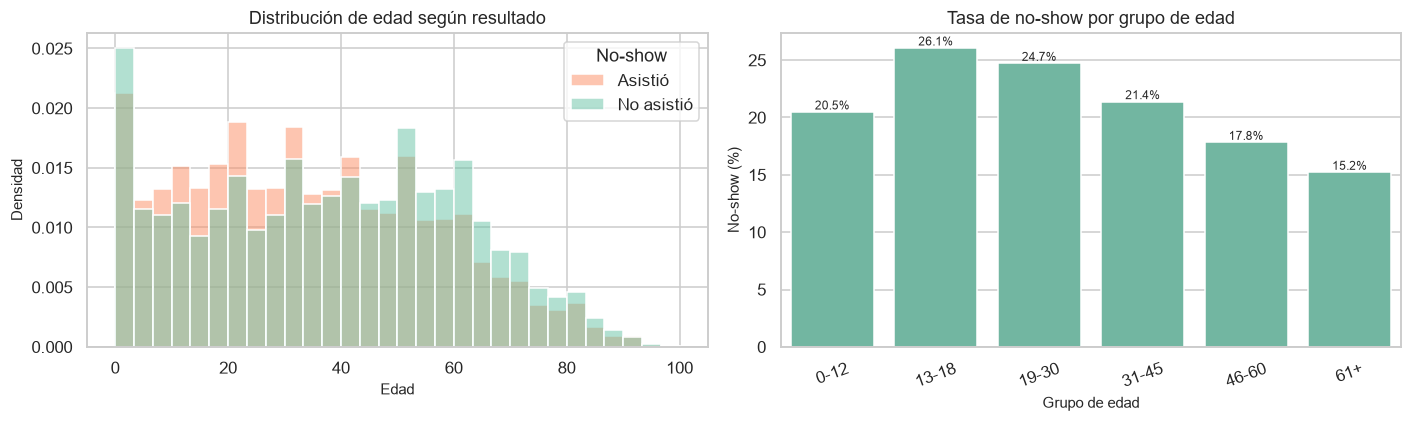

,age_group,n,tasa,tasa_porcentaje
0,0-12,21036,0.204744,20.47
1,13-18,7830,0.260536,26.05
2,19-30,16765,0.247122,24.71
3,31-45,21955,0.213710,21.37
4,46-60,23179,0.178222,17.82
5,61+,19762,0.152110,15.21


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    data=df,
    x="Age",
    hue="no_show",
    bins=30,
    stat="density",
    common_norm=False,
    ax=axes[0],
)
axes[0].set_title("Distribución de edad según resultado")
axes[0].set_xlabel("Edad")
axes[0].set_ylabel("Densidad")
axes[0].legend(title="No-show", labels=["Asistió", "No asistió"])

orden_edad = ["0-12", "13-18", "19-30", "31-45", "46-60", "61+"]
tabla_edad = (
    df.groupby("age_group", observed=True)["no_show"]
    .agg(n="size", tasa="mean")
    .reindex(orden_edad)
    .reset_index()
)
tabla_edad["tasa_porcentaje"] = (tabla_edad["tasa"] * 100).round(2)

sns.barplot(
    data=tabla_edad,
    x="age_group",
    y="tasa_porcentaje",
    ax=axes[1],
)
axes[1].set_title("Tasa de no-show por grupo de edad")
axes[1].set_xlabel("Grupo de edad")
axes[1].set_ylabel("No-show (%)")
axes[1].tick_params(axis="x", rotation=20)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES / "05_age_and_no_show.png", bbox_inches="tight")
plt.show()

display(tabla_edad)
tabla_edad.to_csv(
    REPORTS / "eda_tabla_edad.csv", index=False, encoding="utf-8-sig"
)

**Lectura:** la relación con la edad no es lineal. El grupo de 13–18 años presenta la tasa más alta y el de 61+ la más baja. Esto justifica incluir grupos de edad además de la edad numérica.

## 6. Condición socioeconómica, enfermedades crónicas y género

grupo,No,Sí
variable,,
Alcoholism,20.19,20.15
Diabetes,20.36,18.00
Hipertension,20.90,17.30
Scholarship,19.81,23.74
has_chronic_condition,20.91,17.77


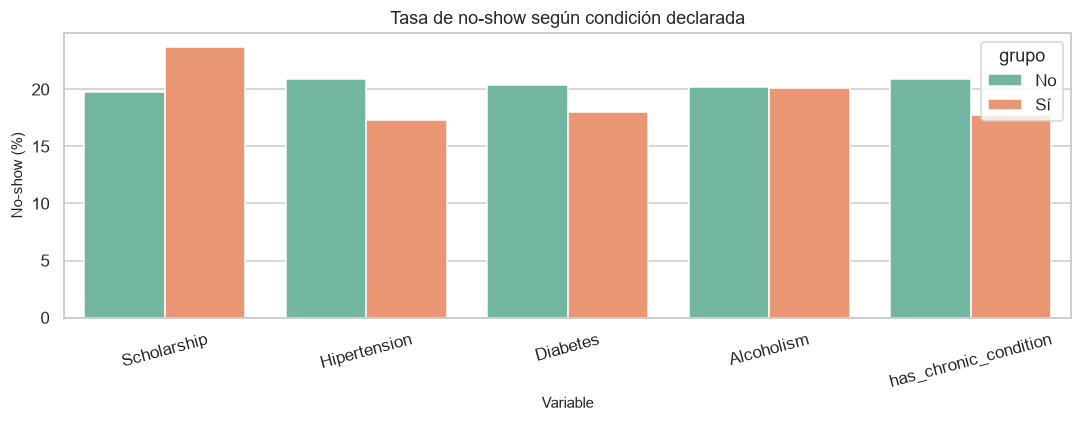

In [32]:
variables_condicion = [
    "Scholarship",
    "Hipertension",
    "Diabetes",
    "Alcoholism",
    "has_chronic_condition",
]

filas = []
for variable in variables_condicion:
    for valor in [0, 1]:
        subset = df[df[variable] == valor]
        filas.append(
            {
                "variable": variable,
                "grupo": "Sí" if valor == 1 else "No",
                "n": len(subset),
                "tasa": subset["no_show"].mean() * 100,
            }
        )
tabla_condiciones = pd.DataFrame(filas)
display(
    tabla_condiciones.pivot(index="variable", columns="grupo", values="tasa").round(2)
)
tabla_condiciones.to_csv(
    REPORTS / "eda_tabla_condiciones.csv", index=False, encoding="utf-8-sig"
)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(
    data=tabla_condiciones,
    x="variable",
    y="tasa",
    hue="grupo",
    ax=ax,
)
ax.set_title("Tasa de no-show según condición declarada")
ax.set_xlabel("Variable")
ax.set_ylabel("No-show (%)")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(FIGURES / "06_conditions_and_no_show.png", bbox_inches="tight")
plt.show()

,Gender,n,tasa,tasa_porcentaje
0,F,71840,0.203146,20.31
1,M,38687,0.199679,19.97


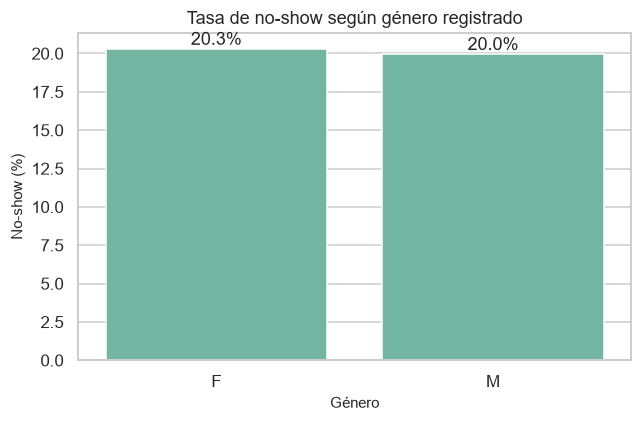

In [33]:
tabla_genero = (
    df.groupby("Gender", observed=True)["no_show"]
    .agg(n="size", tasa="mean")
    .reset_index()
)
tabla_genero["tasa_porcentaje"] = (tabla_genero["tasa"] * 100).round(2)
display(tabla_genero)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=tabla_genero, x="Gender", y="tasa_porcentaje", ax=ax)
ax.set_title("Tasa de no-show según género registrado")
ax.set_xlabel("Género")
ax.set_ylabel("No-show (%)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
plt.tight_layout()
plt.savefig(FIGURES / "07_gender_no_show.png", bbox_inches="tight")
plt.show()

**Lectura:** la beca se asocia a más ausentismo, mientras que hipertensión y diabetes se asocian a menos. El género no muestra una diferencia relevante. Estas asociaciones pueden reflejar composición social y uso del sistema, no efectos causales.

## 7. Barrios

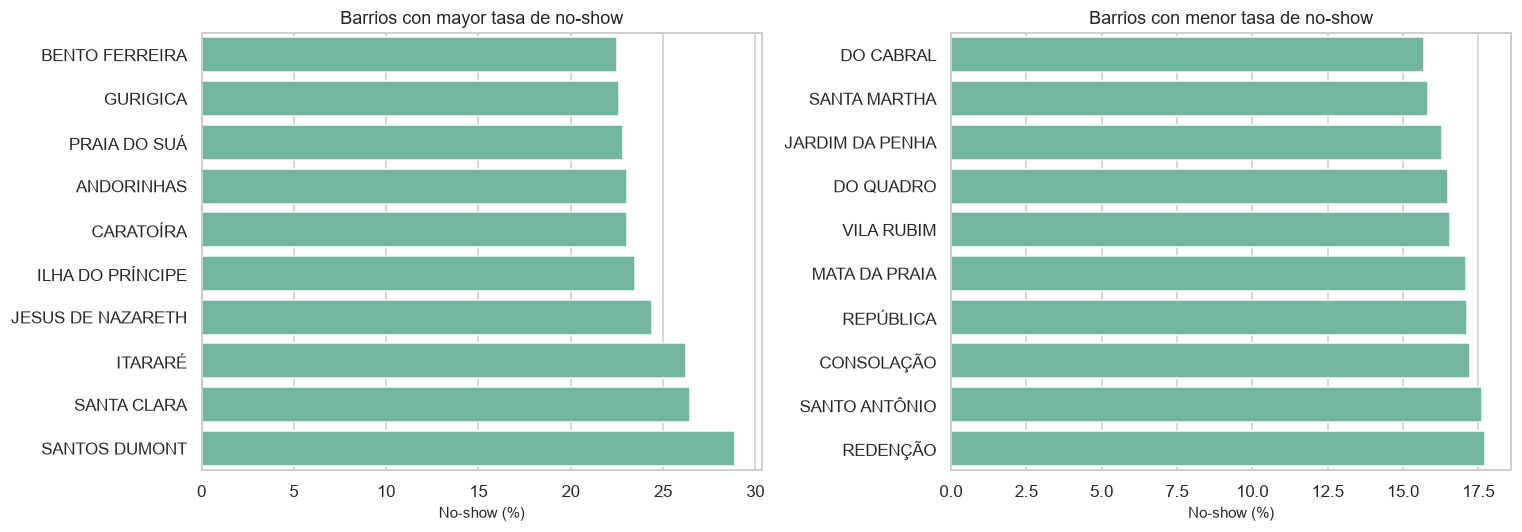

In [34]:
barrios = (
    df.groupby("Neighbourhood", observed=True)["no_show"]
    .agg(n="size", tasa="mean")
    .query("n >= 500")
    .sort_values("tasa", ascending=False)
)
barrios["tasa_porcentaje"] = (barrios["tasa"] * 100).round(2)
barrios.to_csv(REPORTS / "eda_tabla_barrios.csv", encoding="utf-8-sig")

top_barrios = barrios.head(10)
bottom_barrios = barrios.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(
    data=top_barrios.reset_index(),
    y="Neighbourhood",
    x="tasa_porcentaje",
    ax=axes[0],
    orient="h",
    order=top_barrios.index.tolist(),
)
axes[0].set_title("Barrios con mayor tasa de no-show")
axes[0].set_xlabel("No-show (%)")
axes[0].set_ylabel("")
axes[0].invert_yaxis()

sns.barplot(
    data=bottom_barrios.reset_index(),
    y="Neighbourhood",
    x="tasa_porcentaje",
    ax=axes[1],
    orient="h",
    order=bottom_barrios.index.tolist(),
)
axes[1].set_title("Barrios con menor tasa de no-show")
axes[1].set_xlabel("No-show (%)")
axes[1].set_ylabel("")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig(FIGURES / "08_neighbourhood_no_show.png", bbox_inches="tight")
plt.show()

**Lectura:** hay variación geográfica, pero debe interpretarse con cautela. El barrio puede ser un proxy de condiciones socioeconómicas, acceso y composición etaria. No se usarán los barrios para estigmatizar ni para negar atención.

## 8. Correlaciones

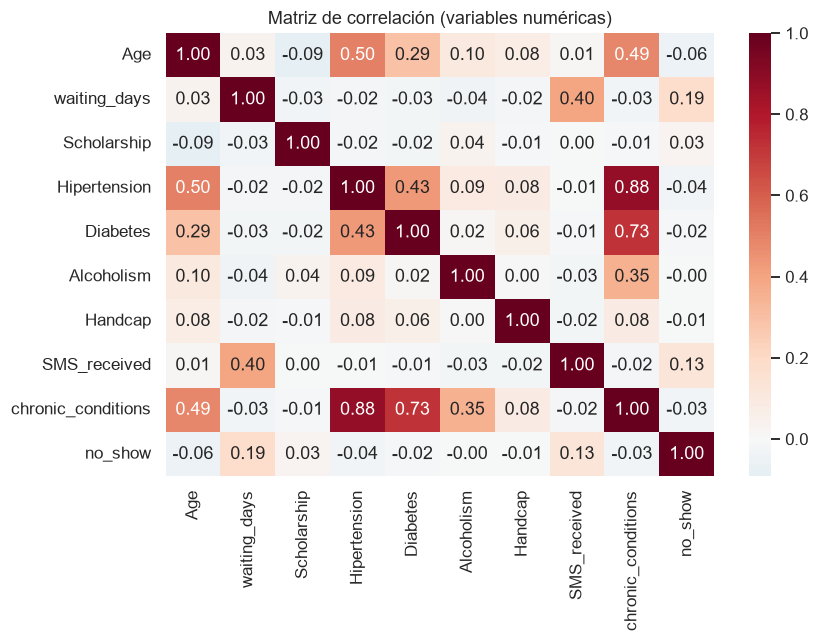

In [35]:
numericas = [
    "Age",
    "waiting_days",
    "Scholarship",
    "Hipertension",
    "Diabetes",
    "Alcoholism",
    "Handcap",
    "SMS_received",
    "chronic_conditions",
    "no_show",
]
corr = df[numericas].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    ax=ax,
)
ax.set_title("Matriz de correlación (variables numéricas)")
plt.tight_layout()
plt.savefig(FIGURES / "09_correlation_heatmap.png", bbox_inches="tight")
plt.show()

## 9. Serie temporal de turnos y no-show

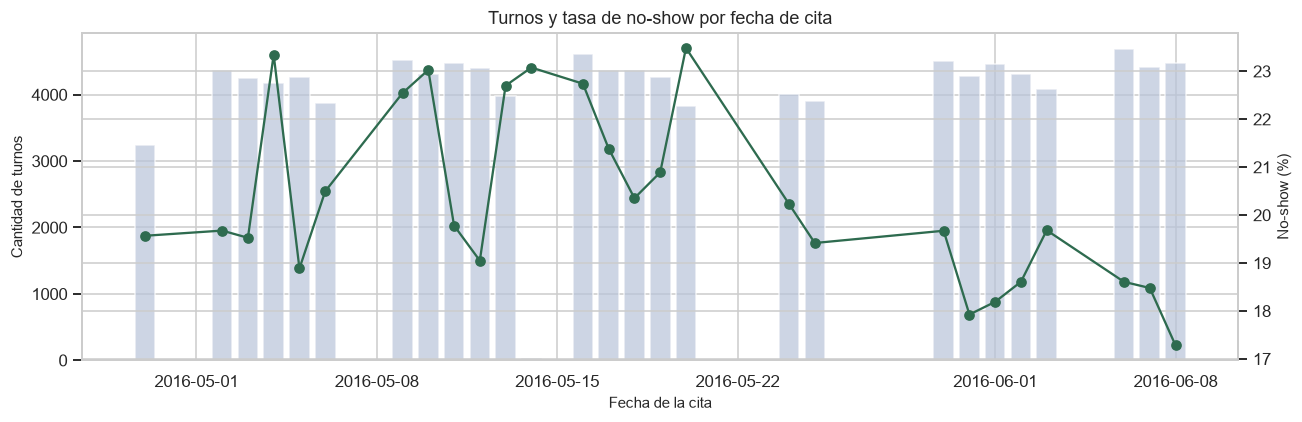

,appointment_date,n,tasa,tasa_porcentaje
0,2016-04-29,3235,0.195672,19.567233
1,2016-05-02,4376,0.196755,19.675503
2,2016-05-03,4256,0.195254,19.525376
3,2016-05-04,4168,0.233445,23.344530
4,2016-05-05,4273,0.188860,18.886029


In [36]:
serie = (
    df.groupby("appointment_date", observed=True)["no_show"]
    .agg(n="size", tasa="mean")
    .reset_index()
)
serie["tasa_porcentaje"] = serie["tasa"] * 100
serie["appointment_date"] = pd.to_datetime(serie["appointment_date"])

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(
    serie["appointment_date"],
    serie["n"],
    color="#B8C4D9",
    alpha=0.7,
    label="Turnos",
)
ax1.set_title("Turnos y tasa de no-show por fecha de cita")
ax1.set_xlabel("Fecha de la cita")
ax1.set_ylabel("Cantidad de turnos")

ax2 = ax1.twinx()
ax2.plot(
    serie["appointment_date"],
    serie["tasa_porcentaje"],
    color="#2E6B4F",
    marker="o",
    linewidth=1.5,
    label="No-show (%)",
)
ax2.set_ylabel("No-show (%)")

plt.tight_layout()
plt.savefig(FIGURES / "10_time_series.png", bbox_inches="tight")
plt.show()

display(serie.head())

## 10. Resumen de hallazgos

In [37]:
resumen = {
    "turnos": int(len(df)),
    "tasa_no_show": round(float(df["no_show"].mean()), 4),
    "pacientes_unicos": int(df["PatientId"].nunique()),
    "barrios": int(df["Neighbourhood"].nunique()),
    "no_show_por_demora": {
        row["waiting_days_bucket"]: round(float(row["tasa_porcentaje"]), 2)
        for _, row in tabla_demora.iterrows()
    },
    "no_show_por_sms": {
        row["grupo"]: round(float(row["tasa_porcentaje"]), 2)
        for _, row in tabla_sms.iterrows()
    },
    "no_show_por_edad": {
        row["age_group"]: round(float(row["tasa_porcentaje"]), 2)
        for _, row in tabla_edad.iterrows()
    },
    "barrios_mayor_no_show": top_barrios["tasa_porcentaje"].to_dict(),
    "barrios_menor_no_show": bottom_barrios["tasa_porcentaje"].to_dict(),
}

with open(REPORTS / "eda_resumen.json", "w", encoding="utf-8") as file:
    json.dump(resumen, file, ensure_ascii=False, indent=2)

hallazgos = pd.DataFrame(
    [
        [
            "Desbalance del target",
            "20,19 % de no-show; accuracy no es suficiente.",
        ],
        [
            "Demora",
            "0 días: 4,6 %; 1–7 días: 24,1 %; 8–14: 30,5 %; 15–30: 32,6 %; >30: 33,0 %.",
        ],
        [
            "SMS",
            "Con SMS: 27,6 %; sin SMS: 16,7 %. Asociación, no causalidad.",
        ],
        [
            "Edad",
            "13–18 años: 26,1 %; 61+: 15,2 %. Relación no lineal.",
        ],
        [
            "Barrio",
            "Variación aproximada de 15,7 % a 28,9 % en barrios con n≥500.",
        ],
        [
            "Género",
            "Diferencia muy pequeña: 20,3 % vs 20,0 %.",
        ],
    ],
    columns=["hallazgo", "lectura"],
)
display(hallazgos)
hallazgos.to_csv(REPORTS / "eda_hallazgos.csv", index=False, encoding="utf-8-sig")
print("Resumen guardado en reports/eda_resumen.json")

,hallazgo,lectura
0,Desbalance del target,"20,19 % de no-show; accuracy no es suficiente."
1,Demora,"0 días: 4,6 %; 1–7 días: 24,1 %; 8–14: 30,5 %;..."
2,SMS,"Con SMS: 27,6 %; sin SMS: 16,7 %. Asociación, ..."
3,Edad,"13–18 años: 26,1 %; 61+: 15,2 %. Relación no l..."
4,Barrio,"Variación aproximada de 15,7 % a 28,9 % en bar..."
5,Género,"Diferencia muy pequeña: 20,3 % vs 20,0 %."


Resumen guardado en reports/eda_resumen.json


## 11. Conclusiones del EDA

1. **El target está desbalanceado**: 20,19 % de no-show. El accuracy por sí solo no sirve; hay que mirar recall, F1, ROC-AUC y PR-AUC.
2. **La demora es el predictor operativo más claro**: los turnos del mismo día tienen una tasa muy baja; a partir de la primera semana, la tasa se estabiliza alrededor de 30 %.
3. **El SMS no debe interpretarse como causal**: el grupo con SMS tiene más no-show, probablemente porque el mensaje se envía a pacientes de mayor riesgo.
4. **La edad tiene una relación no lineal**: los adolescentes y adultos jóvenes tienen más ausentismo que los adultos mayores.
5. **Hay variación por barrio**, pero puede reflejar diferencias socioeconómicas y de acceso; no debe usarse para estigmatizar.
6. **El género no aporta una señal fuerte**: la diferencia descriptiva es muy pequeña.